<a href="https://colab.research.google.com/github/kollenur-student/DM2026-Lab1-Announcement/blob/main/MIS590_W7_Lab_Exercise_stu_revised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 Lab: Neural Reranking and Attention
**MIS590: Information Retrieval · Guided Colab exercise**

Explore how a BERT cross-encoder scores query–passage pairs, how fine-tuning changes
those scores, and what attention visualizations can and cannot tell us.
**All code is complete. Run the cells as supplied; no code changes are required.**

**Learning goals**

- Distinguish separate query/document encoding from a joint cross-encoder.
- Explain pretrained encoder weights, an untrained classification head, and fine-tuning.
- Use development data for model selection and held-out queries for retrieval evaluation.
- Explain the candidate-recall limit of a two-stage retrieval pipeline.
- Read before/after representations and attention without treating a plot as causal proof.

**Class format:** about 90 minutes, including eight required pair discussions of
about three minutes each and an individual exit ticket. Enter both classmates' names.
Alternate who leads. Everyone saves their own notebook and records the shared responses.
The exit ticket is individual. No implementation marks are required.


**My name:** _Enter here._

**Classmate:** _Enter here._

**Date / section:** _Enter here._


## 1. Colab setup · 5 minutes

Upload this notebook to [Colab](https://colab.research.google.com/) and save a copy.
A **T4 GPU**, if available, is useful for fine-tuning: Runtime → Change runtime type.
The supplied small BERT also supports a CPU runtime; an A100 is unnecessary.
Run the installation cell before imports. After it finishes, select **Runtime →
Restart session**, then continue from the imports cell. Do not rerun the installation
cell after restarting. Ask your instructor for help if a cell fails.

Internet is needed for packages, the first public checkpoint download, and
BertViz’s interactive display libraries. The section flowcharts are embedded in this notebook. No API key,
external TSV file, cloud storage mount, or experiment-tracking account is required.
The checkpoint is `prajjwal1/bert-tiny`, a small pretrained **BERT architecture with
two layers and 128 hidden dimensions**, selected for classroom runtime. It is not
BERT-base or a strong production reranker. See its model card in the references.


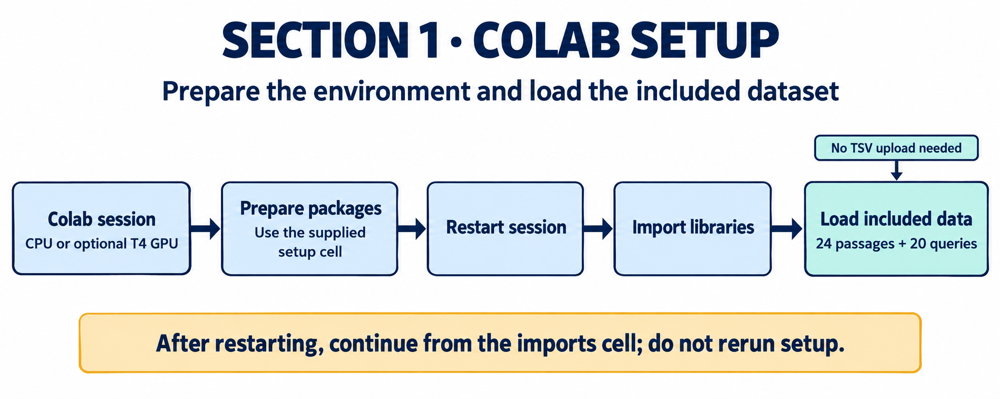

In [ ]:
%pip install -q "huggingface-hub==0.36.2" "torch>=2.6,<3" "transformers==4.57.1" "scikit-learn==1.7.2" "matplotlib==3.10.7" "pandas>=2.2,<3" "bertviz==1.4.1"


In [ ]:
import copy
import json
import math
import random
import re
from pathlib import Path
from time import perf_counter
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from IPython.display import display, HTML
from bertviz import head_view

SEED = 114514
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
EPOCHS, BATCH_SIZE, MAX_LENGTH = 8, 32, 96
LEARNING_RATE, WEIGHT_DECAY = 3e-4, 0.01
K, CANDIDATE_K = 3, 5
RUNTIME_DIR = Path("w7_lab_runtime")
RUNTIME_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", None)
print("Device:", DEVICE, "| fixed seed:", SEED)
for package in ["torch", "transformers", "scikit-learn", "matplotlib", "pandas", "bertviz"]:
    print(f"{package}: {version(package)}")
print("Seeds reduce variation; different hardware can still produce different results.")


Device: cuda | fixed seed: 114514
torch: 2.11.0+cu130
transformers: 4.57.1
scikit-learn: 1.7.2
matplotlib: 3.10.7
pandas: 2.2.3
bertviz: 1.4.1
Seeds reduce variation; different hardware can still produce different results.


### Included handbook and judgments

We reuse the fictional graduate-support handbook from Week 5 for continuity.
All 24 passages, 20 queries, and binary relevance judgments are included below.
A relevant passage directly supports an answer. These are teaching judgments,
not real university policies or an independently collected benchmark.

The task is to rank **known handbook passages for new query wording**. Documents
appear in all splits, while query IDs and query text are disjoint. This evaluates
generalization to held-out queries, not to unseen documents or unseen institutions.


In [ ]:
passages = [{'source_id': 'S01',
  'title': 'Library access and loans',
  'topic': 'library',
  'year': 2026,
  'text': 'During exam weeks, graduate students can study overnight in Library Room L201. The room '
          'is open 24 hours with a student card. Regular reading rooms close at 22:00. Overnight '
          'access does not include the book stacks.',
  'doc_id': 'S01-p1'},
 {'source_id': 'S01',
  'title': 'Library access and loans',
  'topic': 'library',
  'year': 2026,
  'text': 'Graduate students may borrow library books for 21 days and renew them online if no '
          'other reader has reserved them. Printed journals stay inside the library. Late book '
          'returns temporarily suspend borrowing privileges.',
  'doc_id': 'S01-p2'},
 {'source_id': 'S02',
  'title': 'Research computing service',
  'topic': 'computing',
  'year': 2026,
  'text': 'Graduate students can reserve a shared T4 GPU for model inference or small machine '
          'learning experiments. Each reservation lasts at most two hours. Reserve a slot through '
          'the Research Computing portal with a university account.',
  'doc_id': 'S02-p1'},
 {'source_id': 'S02',
  'title': 'Research computing service',
  'topic': 'computing',
  'year': 2026,
  'text': 'If the Research Computing portal rejects your login, submit an IT ticket with the error '
          'message and your account ID. Never include your password. GPU booking problems go to '
          'research-computing support rather than the library.',
  'doc_id': 'S02-p2'},
 {'source_id': 'S03',
  'title': 'Research data backup',
  'topic': 'research',
  'year': 2026,
  'text': 'The managed research drive keeps daily backup snapshots for 21 days. To recover '
          'accidentally deleted files, open a data-recovery ticket and provide the folder path and '
          'approximate deletion time. Recovery is possible only while a snapshot remains '
          'available.',
  'doc_id': 'S03-p1'},
 {'source_id': 'S03',
  'title': 'Research data backup',
  'topic': 'research',
  'year': 2026,
  'text': 'Files on a personal laptop or an unmanaged lab server are outside the managed research '
          'backup service. Researchers must arrange separate backups for those files. A shared '
          'folder is not automatically a backup.',
  'doc_id': 'S03-p2'},
 {'source_id': 'S04',
  'title': 'Coursework extensions',
  'topic': 'coursework',
  'year': 2026,
  'text': 'Under the 2026 coursework policy, request an assignment extension at least 48 hours '
          'before the deadline using form EXT-02. Explain the reason and proposed new date. The '
          'instructor must approve the request. An email alone does not count as approval.',
  'doc_id': 'S04-p1'},
 {'source_id': 'S04',
  'title': 'Coursework extensions',
  'topic': 'coursework',
  'year': 2026,
  'text': 'For a missed coursework deadline caused by an unexpected emergency, contact the course '
          'instructor as soon as possible and attach an explanation. The instructor considers late '
          'requests individually. This exception does not change the normal EXT-02 procedure.',
  'doc_id': 'S04-p2'},
 {'source_id': 'S05',
  'title': 'Student support appointments',
  'topic': 'support',
  'year': 2026,
  'text': 'Students struggling with sleepless nights, exhaustion, or academic stress can book a '
          'confidential appointment with the Student Support Office. The office offers guidance '
          'and referrals. An appointment request is separate from a coursework extension request.',
  'doc_id': 'S05-p1'},
 {'source_id': 'S05',
  'title': 'Student support appointments',
  'topic': 'support',
  'year': 2026,
  'text': 'The Graduate Peer Group meets every Thursday for students who feel isolated during '
          'thesis writing. Students can share experiences about workload and research setbacks. '
          'Joining a peer meeting does not book a confidential Student Support Office appointment.',
  'doc_id': 'S05-p2'},
 {'source_id': 'S06',
  'title': 'Conference expenses',
  'topic': 'finance',
  'year': 2026,
  'text': 'To apply for reimbursement of travel cost, submit the original receipts, proof of attendance, and the approved travel '
          'authorization. ',
  'doc_id': 'S06-p1'},
 {'source_id': 'S06',
  'title': 'Conference expenses',
  'topic': 'finance',
  'year': 2026,
  'text': 'Conference travel needs supervisor approval before booking transport or accommodation. '
          'The department can reimburse approved expenses up to the authorized budget. A travel '
          'approval does not grant extra time for coursework.',
  'doc_id': 'S06-p2'},
 {'source_id': 'S07',
  'title': 'Group work and meeting rooms',
  'topic': 'coursework',
  'year': 2026,
  'text': 'If a group member stops contributing to a course project, keep a record of assigned '
          'tasks, messages, and completed work. Discuss the problem with the team, then contact '
          'the course instructor with the record if it remains unresolved.',
  'doc_id': 'S07-p1'},
 {'source_id': 'S07',
  'title': 'Group work and meeting rooms',
  'topic': 'coursework',
  'year': 2026,
  'text': 'Graduate students may reserve meeting room G12 for group discussions. Each booking '
          'lasts at most two hours. Cancel a reservation you cannot use so that another group can '
          'book the room.',
  'doc_id': 'S07-p2'},
 {'source_id': 'S08',
  'title': 'Research participation and ethics',
  'topic': 'research',
  'year': 2026,
  'text': 'Research involving interviews with human participants requires an ethics review before '
          'recruitment begins. Submit the study plan and consent materials to the research ethics '
          'office. Supervisor permission alone does not replace the ethics review.',
  'doc_id': 'S08-p1'},
 {'source_id': 'S08',
  'title': 'Research participation and ethics',
  'topic': 'research',
  'year': 2026,
  'text': 'For a project using an existing public dataset, check its license and whether it '
          'contains personal information before reuse. Ask the research ethics office if you are '
          'unsure whether a review is required. A public download does not automatically permit '
          'every research use.',
  'doc_id': 'S08-p2'},
 {'source_id': 'S09',
  'title': 'Printing and computer help',
  'topic': 'computing',
  'year': 2026,
  'text': 'Students can print from the university print queue after signing in with a student '
          'account. If a printer jams, report its location to the service desk. Repeatedly sending '
          'the same job can consume the printing quota.',
  'doc_id': 'S09-p1'},
 {'source_id': 'S09',
  'title': 'Printing and computer help',
  'topic': 'computing',
  'year': 2026,
  'text': 'If a computer repeatedly shows a blue screen after restarting, record the error code '
          'and contact the IT service desk. The IT service desk troubleshoots operating system '
          'problems. It does not restore files from the managed research drive.',
  'doc_id': 'S09-p2'},
 {'source_id': 'S10',
  'title': 'Attribution in coursework',
  'topic': 'coursework',
  'year': 2026,
  'text': 'Cite books, articles, websites, and other sources that contribute ideas or wording to '
          'an assignment. Put copied wording in quotation marks and include a citation. Changing a '
          'few words does not remove the need to attribute the source.',
  'doc_id': 'S10-p1'},
 {'source_id': 'S10',
  'title': 'Attribution in coursework',
  'topic': 'coursework',
  'year': 2026,
  'text': 'For coursework that permits AI assistance, disclose the tool and describe how you used '
          'it. Check any generated citations against the actual sources. The course instructor '
          'sets the permitted uses for each assignment.',
  'doc_id': 'S10-p2'},
 {'source_id': 'S11',
  'title': 'Archived coursework extensions',
  'topic': 'coursework',
  'year': 2024,
  'text': 'Archived 2024 coursework policy: students requested an assignment extension at least 72 '
          'hours before the deadline using form EXT-01. This archived rule has been replaced by '
          'the 2026 policy and is retained only for historical comparison.',
  'doc_id': 'S11-p1'},
 {'source_id': 'S11',
  'title': 'Archived coursework extensions',
  'topic': 'coursework',
  'year': 2024,
  'text': 'Under the archived 2024 procedure, students delivered the signed EXT-01 form to the '
          'teaching office. This historical submission procedure is no longer the current '
          'coursework extension process.',
  'doc_id': 'S11-p2'},
 {'source_id': 'S12',
  'title': 'Equipment loans',
  'topic': 'equipment',
  'year': 2026,
  'text': 'Graduate students may borrow a loan laptop from the Equipment Office for seven days. '
          'Bring a student card and return the laptop with its charger. The equipment loan service '
          'is separate from library book borrowing.',
  'doc_id': 'S12-p1'},
 {'source_id': 'S12',
  'title': 'Equipment loans',
  'topic': 'equipment',
  'year': 2026,
  'text': 'A microscope booking lasts at most two hours and requires lab safety training. Reserve '
          'the instrument through the Equipment Office. A microscope reservation provides no '
          'access to the Research Computing GPU service.',
  'doc_id': 'S12-p2'}]

doc_ids = [p["doc_id"] for p in passages]
doc_by_id = {p["doc_id"]: p for p in passages}
texts = [p["text"] for p in passages]
assert len(passages) == len(set(doc_ids)) == 24
display(pd.DataFrame(passages)[["doc_id", "title", "year"]])


,doc_id,title,year
0,S01-p1,Library access and loans,2026
1,S01-p2,Library access and loans,2026
2,S02-p1,Research computing service,2026
3,S02-p2,Research computing service,2026
4,S03-p1,Research data backup,2026
5,S03-p2,Research data backup,2026
6,S04-p1,Coursework extensions,2026
7,S04-p2,Coursework extensions,2026
8,S05-p1,Student support appointments,2026
9,S05-p2,Student support appointments,2026


In [ ]:
queries = [{'query_id': 'T01',
  'text': 'Where is the overnight study room during exam weeks?',
  'relevant': ['S01-p1'],
  'split': 'train'},
 {'query_id': 'T02',
  'text': 'How many days can a graduate student borrow a library book?',
  'relevant': ['S01-p2'],
  'split': 'train'},
 {'query_id': 'T03',
  'text': 'How do I reserve a T4 GPU for a research experiment?',
  'relevant': ['S02-p1'],
  'split': 'train'},
 {'query_id': 'T04',
  'text': 'How can I restore deleted files from the managed research drive?',
  'relevant': ['S03-p1'],
  'split': 'train'},
 {'query_id': 'T05',
  'text': 'What form and notice period are required for an assignment extension in 2026?',
  'relevant': ['S04-p1'],
  'split': 'train'},
 {'query_id': 'T06',
  'text': 'Where can I book confidential support for sleepless nights and academic stress?',
  'relevant': ['S05-p1'],
  'split': 'train'},
 {'query_id': 'T07',
  'text': 'What must I submit to claim conference travel reimbursement?',
  'relevant': ['S06-p1'],
  'split': 'train'},
 {'query_id': 'T08',
  'text': 'What should I do when a group project member stops contributing?',
  'relevant': ['S07-p1'],
  'split': 'train'},
 {'query_id': 'T09',
  'text': 'What review is required before interviewing human research participants?',
  'relevant': ['S08-p1'],
  'split': 'train'},
 {'query_id': 'T10',
  'text': 'How do I report a printer jam and avoid wasting the printing quota?',
  'relevant': ['S09-p1'],
  'split': 'train'},
 {'query_id': 'T11',
  'text': 'How should I disclose permitted AI assistance in coursework?',
  'relevant': ['S10-p2'],
  'split': 'train'},
 {'query_id': 'T12',
  'text': 'Where can I borrow a laptop and for how many days?',
  'relevant': ['S12-p1'],
  'split': 'train'},
 {'query_id': 'D01',
  'text': 'Where can I study all night during exams?',
  'relevant': ['S01-p1'],
  'split': 'development'},
 {'query_id': 'D02',
  'text': 'I accidentally erased a folder on the managed research drive. Can I get it back?',
  'relevant': ['S03-p1'],
  'split': 'development'},
 {'query_id': 'D03',
  'text': 'How do I request an assignment extension under the 2026 policy?',
  'relevant': ['S04-p1'],
  'split': 'development'},
 {'query_id': 'D04',
  'text': 'I need a shared graphics processor for a small learning experiment. Where do I book it?',
  'relevant': ['S02-p1'],
  'split': 'development'},
 {'query_id': 'X01',
  'text': 'I barely sleep and feel worn out by graduate school. Who can I talk to?',
  'relevant': ['S05-p1'],
  'split': 'test'},
 {'query_id': 'X02',
  'text': 'After coming home from an academic conference, how do I get my travel costs paid back?',
  'relevant': ['S06-p1'],
  'split': 'test'},
 {'query_id': 'X03',
  'text': 'How long can I keep a borrowed library book or a loan laptop?',
  'relevant': ['S01-p2', 'S12-p1'],
  'split': 'test'},
 {'query_id': 'X04',
  'text': 'May I recruit interview participants after only getting my supervisor to agree?',
  'relevant': ['S08-p1'],
  'split': 'test'}]

train_queries = [q for q in queries if q["split"] == "train"]
dev_queries = [q for q in queries if q["split"] == "development"]
test_queries = [q for q in queries if q["split"] == "test"]
assert len({q["query_id"] for q in queries}) == len(queries)
assert len({q["text"] for q in queries}) == len(queries)
assert all(set(q["relevant"]) <= set(doc_ids) for q in queries)
display(pd.DataFrame(dev_queries)[["query_id", "text", "relevant"]])


,query_id,text,relevant
0,D01,Where can I study all night during exams?,[S01-p1]
1,D02,I accidentally erased a folder on the managed research drive. Can I get it back?,[S03-p1]
2,D03,How do I request an assignment extension under the 2026 policy?,[S04-p1]
3,D04,I need a shared graphics processor for a small learning experiment. Where do I book it?,[S02-p1]


## 2. Query–document interaction and the untrained head · 10 minutes

A dual encoder encodes the query and passage separately, allowing passage vectors
to be cached. A cross-encoder receives **both texts together** and computes a
score for that pair. Its passage representation depends on the query.

BERT pair format is `[CLS] query [SEP] passage [SEP]`. The tokenizer also provides
segment IDs and a padding mask. The relevance label belongs to the **pair**.
The same passage can be relevant to one query and irrelevant to another.


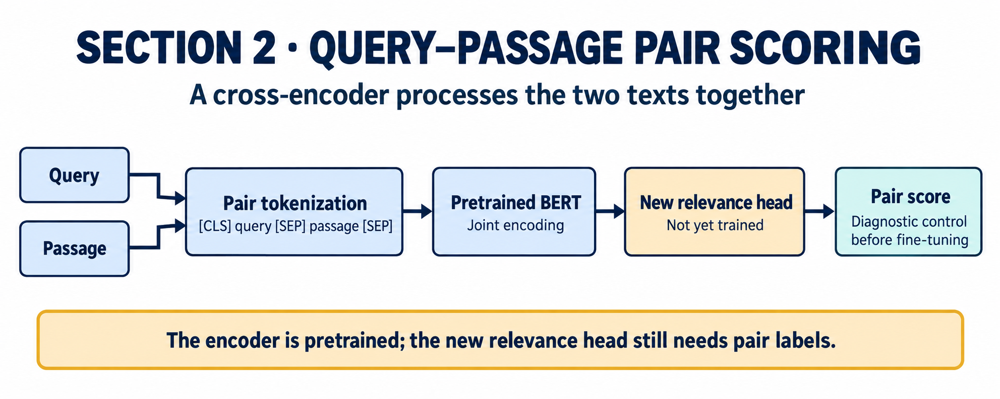

In [ ]:
MODEL_NAME = "prajjwal1/bert-tiny"
MODEL_REVISION = "6f75de8b60a9f8a2fdf7b69cbd86d9e64bcb3837"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, revision=MODEL_REVISION, num_labels=2,
    attn_implementation="eager",  # Explicit attention tensors for the later analysis.
).to(DEVICE)
model.eval()
before_model = copy.deepcopy(model).eval()
print("Layers:", model.config.num_hidden_layers,
      "| heads/layer:", model.config.num_attention_heads,
      "| hidden size:", model.config.hidden_size)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("The encoder is pretrained. The two-class relevance head is newly initialized.")

sample_query = train_queries[4]
sample_doc = doc_by_id["S04-p1"]
sample_inputs = tokenizer(sample_query["text"], sample_doc["text"], return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(sample_inputs["input_ids"][0])
display(pd.DataFrame({"position": range(len(tokens)), "token": tokens,
                      "segment_id": sample_inputs["token_type_ids"][0].tolist(),
                      "mask": sample_inputs["attention_mask"][0].tolist()}))

print("Doc:",sample_doc['text'],"\n")

print("Query T05:",sample_query['text'])
print("S04-p1 label for T05: 1","\n")

print("Query T04:",train_queries[2]['text'])
print("S04-p1 label for T03: 0","\n")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/17.8M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at prajjwal1/bert-tiny and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Layers: 2 | heads/layer: 2 | hidden size: 128
Parameters: 4,386,178
The encoder is pretrained. The two-class relevance head is newly initialized.


,position,token,segment_id,mask
0,0,[CLS],0,1
1,1,what,0,1
2,2,form,0,1
3,3,and,0,1
4,4,notice,0,1
...,...,...,...,...
63,63,count,1,1
64,64,as,1,1
65,65,approval,1,1
66,66,.,1,1


Doc: Under the 2026 coursework policy, request an assignment extension at least 48 hours before the deadline using form EXT-02. Explain the reason and proposed new date. The instructor must approve the request. An email alone does not count as approval. 

Query T05: What form and notice period are required for an assignment extension in 2026?
S04-p1 label for T05: 1 

Query T04: How do I reserve a T4 GPU for a research experiment?
S04-p1 label for T03: 0 



### Required discussion 1: Why encode the pair? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. Why can S04-p1 have label 1 for T05 but label 0 for T03? What does this tell you about the training input?
2. Use the token table to identify the query and passage segments. Why can a cross-encoder not simply reuse one fixed passage vector for every query?


**Discussion 1 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


### Scoring and evaluation helpers, all provided

We rank pairs by `logit(relevant) − logit(not relevant)`. Softmax would give the
same ordering for a two-class head, but neither number is a calibrated probability.
Before fine-tuning, the head has never learned relevance. Its ranking is a
**diagnostic control**, not a trained BERT relevance baseline.

The code includes ordinary ranked-list **Average Precision (AP)**, Precision@3,
Recall@3, and RR@3. MAP and MRR average AP and RR across queries. AP divides by
the total number of relevant passages in the corpus, including any not retrieved.
Equal scores use a stable ID tie-break. We avoid an external `pytrec_eval` build.


In [ ]:
def rank_scores(ids, scores):
    return sorted(zip(ids, map(float, scores)), key=lambda row: (-row[1], row[0]))

def show_ranking(ranking, relevant, limit=K):
    rows = [{"rank": i, "doc_id": did, "score": score,
             "relevant": int(did in relevant), "text": doc_by_id[did]["text"]}
            for i, (did, score) in enumerate(ranking[:limit], 1)]
    return (pd.DataFrame(rows).style
            .set_properties(subset=["text"], **{"white-space":"normal", "text-align":"left", "max-width":"45em"})
            .format({"score":"{:.4f}"}))

def rank_metrics(ranked_ids, relevant, k=K):
    assert len(ranked_ids) == len(set(ranked_ids)), "Duplicate result IDs"
    relevant = set(relevant)
    hits, precisions = 0, []
    for rank, did in enumerate(ranked_ids, 1):
        if did in relevant:
            hits += 1
            precisions.append(hits / rank)
    top_hits = len(set(ranked_ids[:k]) & relevant)
    rr = next((1 / r for r,did in enumerate(ranked_ids[:k],1) if did in relevant), 0.0)
    return {"AP": sum(precisions) / len(relevant) if relevant else 0.0,
            "P@3": top_hits / k,
            "Recall@3": top_hits / len(relevant) if relevant else 0.0,
            "RR@3": rr}

toy = rank_metrics(["b", "a", "c"], {"a", "c"})
assert np.isclose(toy["AP"], (1/2 + 2/3) / 2)
assert rank_metrics(["a"], {"a", "c"})["AP"] == 0.5

vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1,2), norm="l2")
lexical_matrix = vectorizer.fit_transform(texts)  # Fit only the document collection.
def lexical_ranking(query):
    scores = (lexical_matrix @ vectorizer.transform([query]).T).toarray().ravel()
    return rank_scores(doc_ids, scores)

@torch.inference_mode()
def pair_scores(which_model, query, ids):
    which_model.eval()
    scores = []
    for start in range(0, len(ids), BATCH_SIZE):
        batch_ids = ids[start:start+BATCH_SIZE]
        inputs = tokenizer([query] * len(batch_ids), [doc_by_id[d]["text"] for d in batch_ids],
                           padding=True, truncation="only_second", max_length=MAX_LENGTH,
                           return_tensors="pt").to(DEVICE)
        logits = which_model(**inputs).logits
        scores.extend((logits[:,1] - logits[:,0]).cpu().tolist())
    return np.asarray(scores)

def neural_ranking(which_model, query, ids=None):
    ids = doc_ids if ids is None else ids
    return rank_scores(ids, pair_scores(which_model, query, ids))

baseline_example = dev_queries[2]
print(baseline_example["query_id"], baseline_example["text"])
print("TF-IDF:")
display(show_ranking(lexical_ranking(baseline_example["text"]), baseline_example["relevant"]))
print("\nPretrained encoder + UNTRAINED relevance head:")
display(show_ranking(neural_ranking(before_model, baseline_example["text"]), baseline_example["relevant"]))


D03 How do I request an assignment extension under the 2026 policy?
TF-IDF:


,rank,doc_id,score,relevant,text
0,1,S04-p1,0.4141,1,"Under the 2026 coursework policy, request an assignment extension at least 48 hours before the deadline using form EXT-02. Explain the reason and proposed new date. The instructor must approve the request. An email alone does not count as approval."
1,2,S11-p1,0.2825,0,Archived 2024 coursework policy: students requested an assignment extension at least 72 hours before the deadline using form EXT-01. This archived rule has been replaced by the 2026 policy and is retained only for historical comparison.
2,3,S11-p2,0.1108,0,"Under the archived 2024 procedure, students delivered the signed EXT-01 form to the teaching office. This historical submission procedure is no longer the current coursework extension process."



Pretrained encoder + UNTRAINED relevance head:


,rank,doc_id,score,relevant,text
0,1,S12-p2,0.3505,0,A microscope booking lasts at most two hours and requires lab safety training. Reserve the instrument through the Equipment Office. A microscope reservation provides no access to the Research Computing GPU service.
1,2,S12-p1,0.3292,0,Graduate students may borrow a loan laptop from the Equipment Office for seven days. Bring a student card and return the laptop with its charger. The equipment loan service is separate from library book borrowing.
2,3,S03-p2,0.3164,0,Files on a personal laptop or an unmanaged lab server are outside the managed research backup service. Researchers must arrange separate backups for those files. A shared folder is not automatically a backup.


### Required discussion 2: What is pretrained? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. The encoder weights are pretrained, but the relevance head is new. Can its initial relevance ranking be trusted? Explain.
2. What changes during fine-tuning in this notebook? Why is a poor initial ranking not evidence that pretrained language representations are useless?


**Discussion 2 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## 3. Training, development, and test queries · 10 minutes

Each query is paired with all 24 passages. Training uses 12 query groups; development
uses four other query groups; test uses four more. The test queries are untouched
by gradient updates and checkpoint selection. Labels and passages are visible for
classroom inspection, but the supplied training procedure never uses the test split.

There are many more negative than positive pairs. Class weights based **only on
training counts** give relevant pairs more weight in cross-entropy. AdamW updates
parameters; weight decay regularizes parameters rather than progressively shrinking
every gradient. All settings are fixed before the test results are examined.


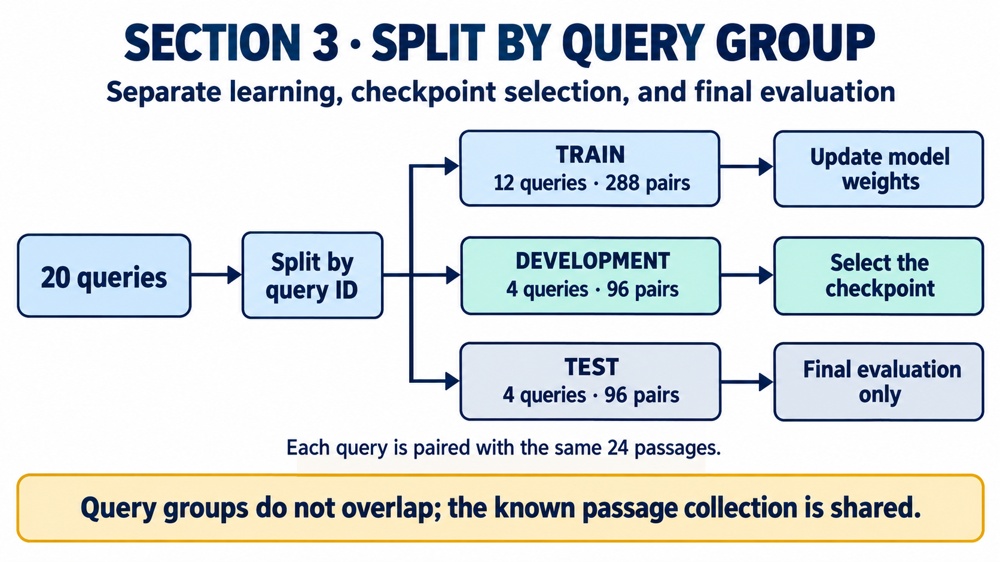

In [ ]:
def make_pairs(query_set):
    return [{"query_id":q["query_id"], "query":q["text"], "doc_id":did,
             "label":int(did in q["relevant"])} for q in query_set for did in doc_ids]

train_pairs = make_pairs(train_queries)
dev_pairs = make_pairs(dev_queries)
test_pairs = make_pairs(test_queries)
query_sets = [{r["query_id"] for r in rows} for rows in [train_pairs,dev_pairs,test_pairs]]
assert not (query_sets[0] & query_sets[1] or query_sets[0] & query_sets[2] or query_sets[1] & query_sets[2])
# Check every pair before truncation: this corpus should fit completely.
pair_lengths = [len(tokenizer(p["query"], doc_by_id[p["doc_id"]]["text"],
                              truncation=False)["input_ids"])
                for p in train_pairs + dev_pairs + test_pairs]
assert max(pair_lengths) <= MAX_LENGTH, "Shorten passages or increase the fixed length."

class PairDataset(Dataset):
    def __init__(self, rows):
        self.encodings = tokenizer([r["query"] for r in rows],
                                   [doc_by_id[r["doc_id"]]["text"] for r in rows],
                                   padding="max_length", truncation="only_second",
                                   max_length=MAX_LENGTH, return_tensors="pt")
        self.labels = torch.tensor([r["label"] for r in rows])
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return {**{k:v[index] for k,v in self.encodings.items()}, "labels":self.labels[index]}

train_data, dev_data = PairDataset(train_pairs), PairDataset(dev_pairs)
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          generator=generator, num_workers=0)
train_eval_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False)
dev_loader = DataLoader(dev_data, batch_size=BATCH_SIZE, shuffle=False)
counts = torch.bincount(train_data.labels, minlength=2).float()
class_weights = (counts.sum() / (2 * counts)).to(DEVICE)
split_table = pd.DataFrame([{"split":name, "queries":len(qs), "pairs":len(rows),
                            "positive_pairs":sum(r["label"] for r in rows)}
                           for name,qs,rows in [("train",train_queries,train_pairs),
                                               ("development",dev_queries,dev_pairs),
                                               ("test",test_queries,test_pairs)]])
display(split_table)
print("Negative / positive training counts:", counts.tolist())
print("Class weights:", class_weights.cpu().tolist())
print("Updates per epoch:", len(train_loader), "| total updates:", EPOCHS * len(train_loader))
print("Maximum untruncated pair length:", max(pair_lengths))


,split,queries,pairs,positive_pairs
0,train,12,288,12
1,development,4,96,4
2,test,4,96,5


Negative / positive training counts: [276.0, 12.0]
Class weights: [0.52173912525177, 12.0]
Updates per epoch: 9 | total updates: 72
Maximum untruncated pair length: 71


### Required discussion 3: Which data makes which decision? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. Use the split table to name the number of training queries and pairs. Why would randomly splitting individual pairs risk putting the same query in training and test?
2. With batch size 32 and eight epochs, how many optimizer updates are planned? Which split selects the checkpoint, and why should test results not select it?


**Discussion 3 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## 4. Fine-tuning and checkpoint selection · 20 minutes

Run the supplied training cell once and watch the epoch log. Both losses use the
same training-derived class weights and evaluation mode. The training loss is
recomputed after each epoch, so it is comparable with development loss.

The notebook keeps a CPU copy of the initial model and saves the **lowest-development-loss**
state to `w7_lab_runtime/best_state.pt`. The initial state (epoch 0) is also eligible.
Only the best file is retained. Runtime files disappear when Colab deletes its session.
Test queries are not scored here. Lower development classification loss need not
imply better ranking metrics on a different query set.


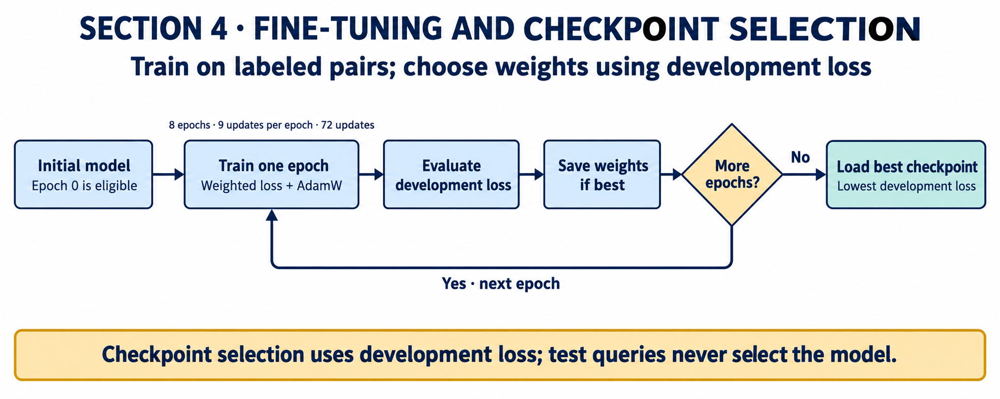

Epoch 1/8: train=0.6807, development=0.6853, best epoch=1
Epoch 2/8: train=0.6870, development=0.7151, best epoch=1
Epoch 3/8: train=0.5802, development=0.6144, best epoch=3
Epoch 4/8: train=0.3851, development=0.4899, best epoch=4
Epoch 5/8: train=0.2490, development=0.4922, best epoch=4
Epoch 6/8: train=0.1522, development=0.5312, best epoch=4
Epoch 7/8: train=0.0937, development=0.6107, best epoch=4
Epoch 8/8: train=0.0534, development=0.8980, best epoch=4


,epoch,train_loss,development_loss
0,0,0.783313,0.760619
1,1,0.680746,0.685301
2,2,0.686990,0.715131
3,3,0.580163,0.614400
4,4,0.385138,0.489865
5,5,0.249029,0.492231
6,6,0.152157,0.531171
7,7,0.093746,0.610692
8,8,0.053402,0.898036


Loaded best epoch: 4 | development loss: 0.4899 | training seconds: 1.41


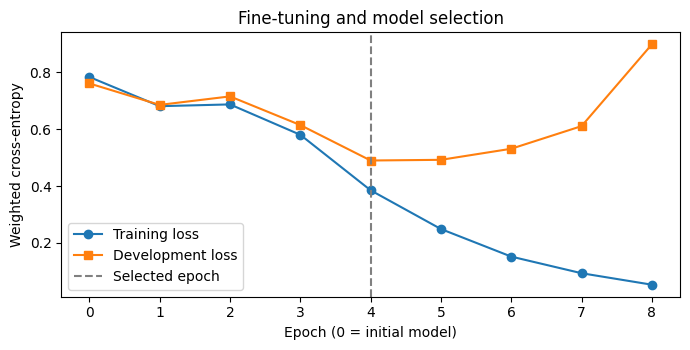

In [ ]:
@torch.inference_mode()
def weighted_loss(which_model, loader):
    which_model.eval()
    total, denominator = 0.0, 0.0
    for batch in loader:
        labels = batch["labels"].to(DEVICE)
        inputs = {k:v.to(DEVICE) for k,v in batch.items() if k != "labels"}
        logits = which_model(**inputs).logits
        total += F.cross_entropy(logits, labels, weight=class_weights, reduction="sum").item()
        denominator += class_weights[labels].sum().item()
    return total / denominator

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
checkpoint_path = RUNTIME_DIR / "best_state.pt"
best_loss, best_epoch = weighted_loss(model, dev_loader), 0
torch.save({k:v.detach().cpu().clone() for k,v in model.state_dict().items()}, checkpoint_path)
history = [{"epoch":0, "train_loss":weighted_loss(model,train_eval_loader),
            "development_loss":best_loss}]
step_count = 0
start = perf_counter()
for epoch in range(1, EPOCHS+1):
    model.train()
    for batch in train_loader:
        labels = batch["labels"].to(DEVICE)
        inputs = {k:v.to(DEVICE) for k,v in batch.items() if k != "labels"}
        optimizer.zero_grad(set_to_none=True)
        logits = model(**inputs).logits
        loss = F.cross_entropy(logits, labels, weight=class_weights)
        assert torch.isfinite(loss), "Non-finite training loss"
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        step_count += 1
    train_loss = weighted_loss(model, train_eval_loader)
    dev_loss = weighted_loss(model, dev_loader)
    history.append({"epoch":epoch, "train_loss":train_loss, "development_loss":dev_loss})
    if dev_loss < best_loss:
        best_loss, best_epoch = dev_loss, epoch
        torch.save({k:v.detach().cpu().clone() for k,v in model.state_dict().items()}, checkpoint_path)
    print(f"Epoch {epoch}/{EPOCHS}: train={train_loss:.4f}, development={dev_loss:.4f}, best epoch={best_epoch}")
training_seconds = perf_counter() - start
assert step_count == EPOCHS * len(train_loader)
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
model.eval()
history_table = pd.DataFrame(history)
display(history_table)
print("Loaded best epoch:",best_epoch,"| development loss:",round(best_loss,4),
      "| training seconds:",round(training_seconds,2))

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(history_table.epoch, history_table.train_loss, marker="o", label="Training loss")
ax.plot(history_table.epoch, history_table.development_loss, marker="s", label="Development loss")
ax.axvline(best_epoch, color="gray", linestyle="--", label="Selected epoch")
ax.set(xlabel="Epoch (0 = initial model)", ylabel="Weighted cross-entropy", title="Fine-tuning and model selection")
ax.legend()
fig.tight_layout()
fig.savefig(RUNTIME_DIR / "training.png", dpi=140)
plt.show()
plt.close(fig)


### Required discussion 4: Why keep an intermediate checkpoint? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. Which epoch was selected? Use its development loss and one other epoch to explain why the final epoch need not be the best choice.
2. If training loss decreases but development loss rises, what would you suspect? Does that observation prove held-out retrieval got better or worse?


**Discussion 4 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## 5. Held-out retrieval performance · 10 minutes

The checkpoint and all settings are now fixed. The next cells evaluate new query
wording on the known collection. Report per-query results as well as their means.
The before/after BERT rankings both use the **classification head on complete pairs**;
they do not substitute cosine similarity of independently encoded `[CLS]` vectors.

AP here is the average of precisions at relevant ranks, divided by all relevant
passages. It has no precision–recall interpolation. With unique scores and complete
binary labels it agrees with scikit-learn's AP definition; score ties may lead to
different treatment. A library name alone does not imply a different metric.


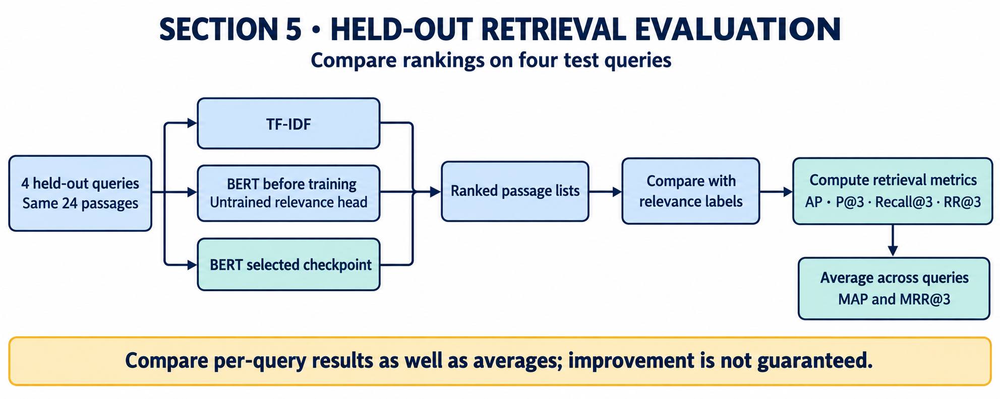

In [ ]:
def evaluate_methods(methods, query_set):
    records = []
    for name, method in methods.items():
        for q in query_set:
            ranking = method(q["text"])
            records.append({"method":name, "query_id":q["query_id"],
                            "top3":", ".join(d for d,_ in ranking[:K]),
                            **rank_metrics([d for d,_ in ranking],q["relevant"])})
    detail = pd.DataFrame(records)
    summary = detail.groupby("method",sort=False)[["AP","P@3","Recall@3","RR@3"]].mean()
    summary.columns = ["MAP","P@3","Recall@3","MRR@3"]
    return detail, summary

methods = {"TF-IDF":lexical_ranking,
           "BERT: untrained head":lambda q: neural_ranking(before_model,q),
           "BERT: selected checkpoint":lambda q: neural_ranking(model,q)}
dev_detail, dev_summary = evaluate_methods(methods,dev_queries)
test_detail, test_summary = evaluate_methods(methods,test_queries)
print("DEVELOPMENT")
display(dev_summary)
print("HELD-OUT QUERY RESULTS")
display(test_detail)
display(test_summary)
for q in [test_queries[0],test_queries[2]]:
    print(q["query_id"],q["text"],"| labeled relevant:",q["relevant"])
    print("Before training:")
    display(show_ranking(neural_ranking(before_model,q["text"]),q["relevant"]))
    print("Selected checkpoint:")
    display(show_ranking(neural_ranking(model,q["text"]),q["relevant"]))


DEVELOPMENT


,MAP,P@3,Recall@3,MRR@3
method,,,,
TF-IDF,1.000000,0.333333,1.0,1.000
BERT: untrained head,0.041667,0.000000,0.0,0.000
BERT: selected checkpoint,0.875000,0.333333,1.0,0.875


HELD-OUT QUERY RESULTS


,method,query_id,top3,AP,P@3,Recall@3,RR@3
0,TF-IDF,X01,"S05-p2, S09-p1, S11-p1",0.076923,0.000000,0.0,0.0
1,TF-IDF,X02,"S06-p2, S06-p1, S05-p1",0.500000,0.333333,1.0,0.5
2,TF-IDF,X03,"S12-p1, S01-p2, S03-p2",1.000000,0.666667,1.0,1.0
3,TF-IDF,X04,"S08-p1, S06-p2, S09-p1",1.000000,0.333333,1.0,1.0
4,BERT: untrained head,X01,"S08-p1, S03-p1, S03-p2",0.041667,0.000000,0.0,0.0
5,BERT: untrained head,X02,"S10-p1, S12-p2, S03-p1",0.043478,0.000000,0.0,0.0
6,BERT: untrained head,X03,"S11-p1, S12-p2, S06-p1",0.063406,0.000000,0.0,0.0
7,BERT: untrained head,X04,"S11-p2, S12-p2, S03-p1",0.041667,0.000000,0.0,0.0
8,BERT: selected checkpoint,X01,"S05-p2, S01-p2, S07-p2",0.166667,0.000000,0.0,0.0
9,BERT: selected checkpoint,X02,"S06-p2, S06-p1, S05-p1",0.500000,0.333333,1.0,0.5


,MAP,P@3,Recall@3,MRR@3
method,,,,
TF-IDF,0.644231,0.333333,0.75,0.625
BERT: untrained head,0.047554,0.000000,0.00,0.000
BERT: selected checkpoint,0.625000,0.333333,0.75,0.625


X01 I barely sleep and feel worn out by graduate school. Who can I talk to? | labeled relevant: ['S05-p1']
Before training:


... (3 outputs left out)

X03 How long can I keep a borrowed library book or a loan laptop? | labeled relevant: ['S01-p2', 'S12-p1']
Before training:


,rank,doc_id,score,relevant,text
0,1,S11-p1,0.2328,0,Archived 2024 coursework policy: students requested an assignment extension at least 72 hours before the deadline using form EXT-01. This archived rule has been replaced by the 2026 policy and is retained only for historical comparison.
1,2,S12-p2,0.2073,0,A microscope booking lasts at most two hours and requires lab safety training. Reserve the instrument through the Equipment Office. A microscope reservation provides no access to the Research Computing GPU service.
2,3,S06-p1,0.2021,0,"To apply for reimbursement of travel cost, submit the original receipts, proof of attendance, and the approved travel authorization."


Selected checkpoint:


,rank,doc_id,score,relevant,text
0,1,S12-p1,0.5095,1,Graduate students may borrow a loan laptop from the Equipment Office for seven days. Bring a student card and return the laptop with its charger. The equipment loan service is separate from library book borrowing.
1,2,S03-p2,0.4813,0,Files on a personal laptop or an unmanaged lab server are outside the managed research backup service. Researchers must arrange separate backups for those files. A shared folder is not automatically a backup.
2,3,S01-p2,0.4112,1,Graduate students may borrow library books for 21 days and renew them online if no other reader has reserved them. Printed journals stay inside the library. Late book returns temporarily suspend borrowing privileges.


### Required discussion 5: Did fine-tuning help retrieval? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. Compare the before/after BERT test MAP. Name one test query and its AP values to support your observation. Improvement is not guaranteed.
2. X03 needs two passages. Can RR@3 be 1 while Recall@3 is only 0.5? Explain what that would mean for an answer to both parts.


**Discussion 5 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## 6. Candidate retrieval followed by neural reranking · 10 minutes

Scoring every document with a cross-encoder is costly in a large collection.
Here TF-IDF retrieves five candidates, then BERT scores only those five pairs.
The earlier all-document BERT ranking is an exhaustive reference for this tiny
corpus, not the scalable pipeline. The following cell really scores only the
candidate pairs, rather than looking up their previously computed full-corpus scores.

Candidate Recall@5 uses all labeled relevant passages in its denominator. The
reranker's top-three recall cannot exceed that candidate recall. This is a quality
ceiling, even if the neural reranker orders its candidate set perfectly.


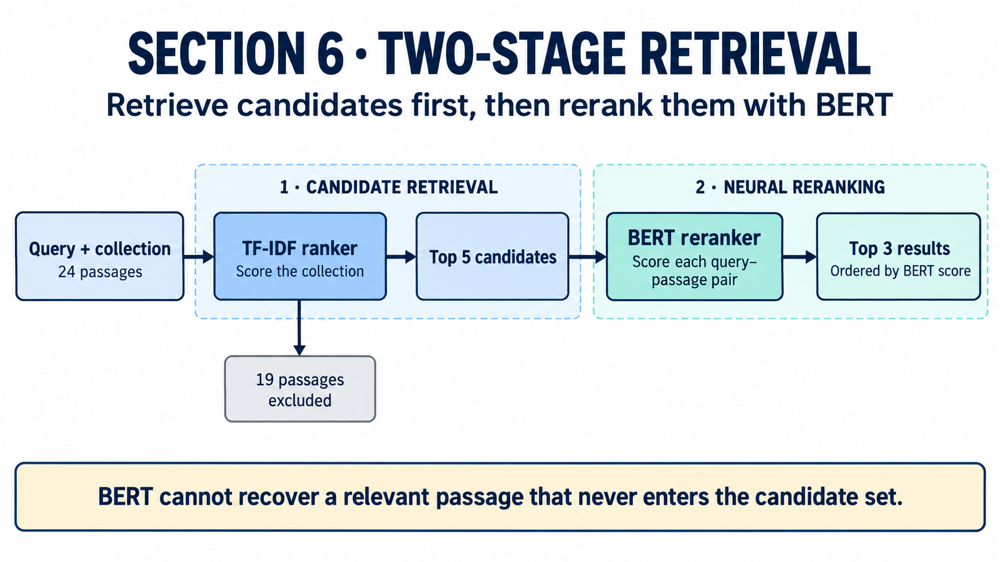

In [ ]:
def two_stage_ranking(query, candidate_k=CANDIDATE_K):
    candidates = [did for did,_ in lexical_ranking(query)[:candidate_k]]
    return neural_ranking(model,query,candidates)

candidate_rows = []
for q in test_queries:
    candidates = [d for d,_ in lexical_ranking(q["text"])[:CANDIDATE_K]]
    reranked = two_stage_ranking(q["text"])
    candidate_recall = len(set(candidates) & set(q["relevant"])) / len(q["relevant"])
    top_recall = rank_metrics([d for d,_ in reranked],q["relevant"])["Recall@3"]
    assert top_recall <= candidate_recall + 1e-9
    candidate_rows.append({"query_id":q["query_id"],"candidate_ids":", ".join(candidates),
                           "candidate_recall@5":candidate_recall,
                           "reranked_recall@3":top_recall,
                           "missing_relevant":", ".join(sorted(set(q["relevant"]) - set(candidates)))})
candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table)
pipeline_detail, pipeline_summary = evaluate_methods({"TF-IDF top5 + BERT":two_stage_ranking},test_queries)
display(pd.concat([test_summary,pipeline_summary]))

# A transparent counterexample: deliberately omit one required X03 passage.
omission_query = test_queries[2]
omitted_id = "S01-p2"
forced_candidates = ["S12-p1"] + [d for d in doc_ids if d not in {omitted_id,"S12-p1"}][:CANDIDATE_K-1]
forced_ranking = neural_ranking(model,omission_query["text"],forced_candidates)
assert omitted_id not in [d for d,_ in forced_ranking]
print("Deliberate omission example: S01-p2 was excluded from candidates and cannot be recovered by reranking.")
print("Real pipeline pair counts per query:",len(doc_ids),"for exhaustive scoring versus",CANDIDATE_K,"for candidate reranking.")


,query_id,candidate_ids,candidate_recall@5,reranked_recall@3,missing_relevant
0,X01,"S05-p2, S09-p1, S11-p1, S04-p2, S07-p2",0.0,0.0,S05-p1
1,X02,"S06-p2, S06-p1, S05-p1, S09-p1, S09-p2",1.0,1.0,
2,X03,"S12-p1, S01-p2, S03-p2, S01-p1, S05-p1",1.0,1.0,
3,X04,"S08-p1, S06-p2, S09-p1, S03-p1, S11-p1",1.0,1.0,


,MAP,P@3,Recall@3,MRR@3
method,,,,
TF-IDF,0.644231,0.333333,0.75,0.625
BERT: untrained head,0.047554,0.000000,0.00,0.000
BERT: selected checkpoint,0.625000,0.333333,0.75,0.625
TF-IDF top5 + BERT,0.583333,0.333333,0.75,0.625


Deliberate omission example: S01-p2 was excluded from candidates and cannot be recovered by reranking.
Real pipeline pair counts per query: 24 for exhaustive scoring versus 5 for candidate reranking.


### Required discussion 6: What can a reranker recover? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. From the candidate table, choose a query and record candidate Recall@5 and reranked Recall@3. If a relevant passage is absent from the candidates, can the reranker return it?
2. Why score only five pairs instead of all 24? What quality–cost tradeoff would remain when the corpus grows much larger?


**Discussion 6 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## 7. Representation changes in a shared projection · 10 minutes

We inspect the final-layer `[CLS]` hidden states for X03 paired with each passage.
These are **query-conditioned pair representations**, not standalone document vectors.
The **red star** shows X03 encoded **on its own**, once with each model, as a query-only
reference. The query text is printed above the plots.

The code fits **one PCA projection jointly on all 50 vectors**: 24 pair vectors and
one query-only vector from each model. Both panels therefore use the same axes.
The query alone and a query–passage pair are different input types. Their distance
in this exploratory plot is **not the cross-encoder's relevance score**, and this
classifier was not trained to retrieve by distance from a standalone query vector.

PCA discards dimensions. Apparent separation in two dimensions does not establish
relevance quality or causal importance. Use retrieval metrics and the original
labels as additional evidence. Circle color indicates the supplied judgment.


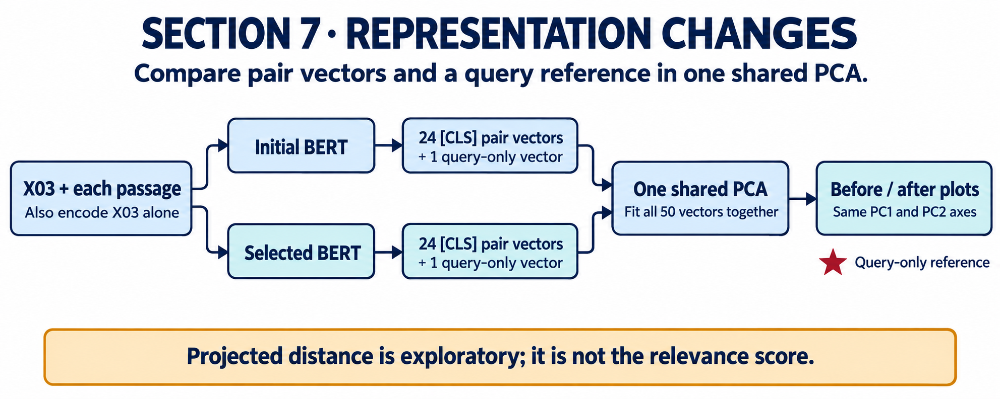

T09: What review is required before interviewing human research participants?


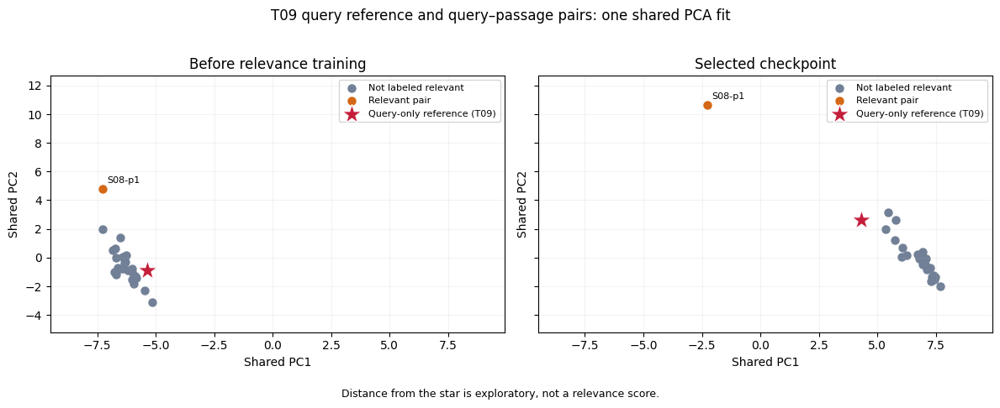

Variance retained in 2D: 0.805


In [ ]:
@torch.inference_mode()
def pair_representations(which_model, query):
    which_model.eval()
    inputs = tokenizer([query]*len(doc_ids), texts, padding=True, truncation="only_second",
                       max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    output = which_model(**inputs, output_hidden_states=True)
    return output.hidden_states[-1][:, 0, :].cpu().numpy()

@torch.inference_mode()
def query_representation(which_model, query):
    # A standalone query reference, using the same final-layer [CLS] extraction.
    which_model.eval()
    inputs = tokenizer(query, truncation=True, max_length=MAX_LENGTH,
                       return_tensors="pt").to(DEVICE)
    output = which_model(**inputs, output_hidden_states=True)
    return output.hidden_states[-1][:, 0, :].cpu().numpy()


# projection_query = test_queries[2]  # X03
projection_query = queries[8]  # T09
print(f'{projection_query["query_id"]}: {projection_query["text"]}')
representation_before = pair_representations(before_model, projection_query["text"])
representation_after = pair_representations(model, projection_query["text"])
query_before = query_representation(before_model, projection_query["text"])
query_after = query_representation(model, projection_query["text"])
vectors_before = np.vstack([representation_before, query_before])
vectors_after = np.vstack([representation_after, query_after])
combined = np.vstack([vectors_before, vectors_after])
assert combined.shape == (2 * (len(doc_ids) + 1), model.config.hidden_size)
pca = PCA(n_components=2, svd_solver="full")
xy = pca.fit_transform(combined)
panel_size = len(doc_ids) + 1
labels = np.array([int(d in projection_query["relevant"]) for d in doc_ids])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, panel, title in zip(axes, [xy[:panel_size], xy[panel_size:]],
                            ["Before relevance training", "Selected checkpoint"]):
    coords, query_point = panel[:-1], panel[-1]
    for label, color in [(0, "#718096"), (1, "#d46816")]:
        mask = labels == label
        ax.scatter(coords[mask, 0], coords[mask, 1], c=color, s=42,
                   label="Relevant pair" if label else "Not labeled relevant")
    ax.scatter(query_point[0], query_point[1], marker="*", s=300, c="#c51e3a",
               edgecolors="white", linewidths=0.8, zorder=5,
               label="Query-only reference (T09)")
    for index, did in enumerate(doc_ids):
        if labels[index]:
            ax.annotate(did, coords[index], xytext=(4, 5),
                        textcoords="offset points", fontsize=8)
    ax.set(title=title, xlabel="Shared PC1", ylabel="Shared PC2")
    ax.margins(0.15)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8, loc="best")
fig.suptitle("T09 query reference and query–passage pairs: one shared PCA fit")
fig.text(0.5, 0.015, "Distance from the star is exploratory, not a relevance score.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.055, 1, 0.96))
fig.savefig(RUNTIME_DIR / "representations.png", dpi=160)
plt.show()
plt.close(fig)
print("Variance retained in 2D:", round(pca.explained_variance_ratio_.sum(), 3))


### Required discussion 7: What can the representation plot show? · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. Locate the red query star in both panels. Describe one before/after change (or lack of change) in the stars or labeled pairs. Why do both panels use the same PCA fit?
2. Could you conclude from this plot alone that fine-tuning improved retrieval? Explain why distance from the query star is not a relevance score, and name another result you should inspect.


**Discussion 7 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## 8. Attention before and after fine-tuning · 15 minutes

In self-attention, each token's learned query projection is compared with key
projections; normalized weights mix value projections:

$$A=\operatorname{softmax}(QK^\top/\sqrt{d_k}),\qquad \mathrm{output}=AV.$$

These Q/K/V projections are internal vectors. The user's IR query is one segment
of the input sequence; the passage tokens also have their own Q/K/V projections.
Our BERT concatenates both texts and uses bidirectional **self-attention**, rather
than a separate encoder–decoder cross-attention module.

The next cell uses BertViz **`head_view()`** for the same X01–S05-p1 pair before
and after relevance training. It keeps **all layers and individual heads**.
Both views initially show the last layer with both heads selected in different colors.

**Try these controls with your classmate; no code edits are needed:**

1. Choose **Sentence A → Sentence B** in the attention filter: A is the IR query;
   B is the passage. The labels may appear as `Sentence A -> Sentence B`.
2. Hover over the query token **sleep** to inspect its outgoing attention links.
3. Click a colored head box to toggle that head; double-click a box to isolate it.
   Compare the **same layer and head** in the before/after views.
4. Change the **Layer** dropdown and look for a different pattern. Layer and head
   numbers are zero-based; this small BERT has layers 0–1 and heads 0–1.

The numeric table below the views gives one fixed comparison: **last layer, head 0**,
from `sleep` to passage tokens. Each full attention row sums to 1; a passage-only
slice can sum to less than 1 because other tokens also receive attention.
The interactive views need internet access to load their display libraries. If a
saved view is blank, rerun this cell after the earlier model cells have completed.

Attention weights describe an internal operation. A large weight alone does not
establish which token caused the final relevance score. The supplied phrase-deletion
comparison is another limited diagnostic, not a complete causal explanation.


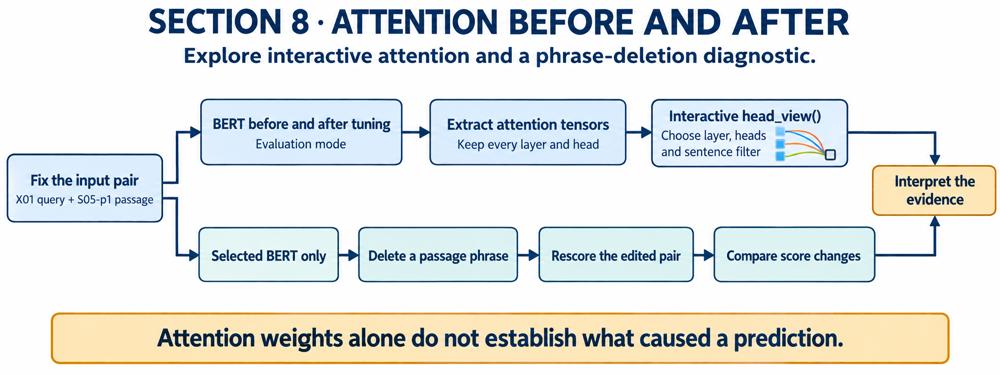

In [ ]:
# attention_query = test_queries[2]["text"]
attention_query = queries[6]["text"]
attention_doc_id = "S06-p1"
attention_text = doc_by_id[attention_doc_id]["text"]
attention_inputs = tokenizer(attention_query, attention_text, return_tensors="pt").to(DEVICE)
attention_tokens = tokenizer.convert_ids_to_tokens(attention_inputs["input_ids"][0].cpu())
segment_ids = attention_inputs["token_type_ids"][0].cpu().tolist()
sentence_b_start = segment_ids.index(1)
special_ids = set(tokenizer.all_special_ids)
input_ids = attention_inputs["input_ids"][0].cpu().tolist()
query_positions = [i for i, tid in enumerate(input_ids) if segment_ids[i] == 0 and tid not in special_ids]
doc_positions = [i for i, tid in enumerate(input_ids) if segment_ids[i] == 1 and tid not in special_ids]

@torch.inference_mode()
def all_attention(which_model):
    which_model.eval()
    output = which_model(**attention_inputs, output_attentions=True)
    attention = tuple(layer.detach().cpu() for layer in output.attentions)
    assert len(attention) == which_model.config.num_hidden_layers
    for layer in attention:
        assert layer.shape[:2] == (1, which_model.config.num_attention_heads)
        assert torch.allclose(layer.sum(dim=-1), torch.ones_like(layer.sum(dim=-1)), atol=1e-5)
    return attention

attention_before = all_attention(before_model)
attention_after = all_attention(model)
default_layer = len(attention_before) - 1
print("Sentence A (query):", attention_query)
print("Sentence B (passage):", attention_text)
print("Compare the same layer/head in both views; try Sentence A -> Sentence A and hover over [CLS].")


Sentence A (query): What must I submit to claim conference travel reimbursement?
Sentence B (passage): To apply for reimbursement of travel cost, submit the original receipts, proof of attendance, and the approved travel authorization. 
Compare the same layer/head in both views; try Sentence A -> Sentence A and hover over [CLS].


In [ ]:
for title, attention, filename in [
    ("Before relevance training", attention_before, "attention_before.html"),
]:
    display(HTML(f"<h3>{title}</h3>"))
    view = head_view(attention, attention_tokens, sentence_b_start=sentence_b_start,
                     layer=default_layer, html_action="return")
    display(view)
    (RUNTIME_DIR / filename).write_text(view.data, encoding="utf-8")



In [ ]:
for title, attention, filename in [
    ("After relevance training: selected checkpoint", attention_after, "attention_after.html"),
]:
    display(HTML(f"<h3>{title}</h3>"))
    view = head_view(attention, attention_tokens, sentence_b_start=sentence_b_start,
                     layer=default_layer, html_action="return")
    display(view)
    (RUNTIME_DIR / filename).write_text(view.data, encoding="utf-8")

In [ ]:
# A fixed single-head table complements the interactive views; heads are not averaged.
table_head = 0
weights_before = attention_before[default_layer][0, table_head].numpy()
weights_after = attention_after[default_layer][0, table_head].numpy()
focus_position = next(i for i in query_positions if attention_tokens[i] == "claim")
attention_table = pd.DataFrame({
    "position": doc_positions,
    "token": [attention_tokens[i] for i in doc_positions],
    "before": weights_before[focus_position, doc_positions],
    "after": weights_after[focus_position, doc_positions],
})
attention_table["change"] = attention_table["after"] - attention_table["before"]
print(f"Numeric comparison: layer {default_layer}, head {table_head}, outgoing attention from sleep")
display(attention_table.sort_values("after", ascending=False).head(8))
print("Full attention rows sum to 1; passage-only slice mass for sleep:",
      round(float(weights_before[focus_position, doc_positions].sum()), 4), "before,",
      round(float(weights_after[focus_position, doc_positions].sum()), 4), "after")
# To apply for reimbursement of travel cost, submit the original receipts, proof of attendance, and the approved travel authorization
variants = {"Original":attention_text,
            "Remove important phrase":attention_text.replace("reimbursement of travel cost", ""),
            "Remove documents":attention_text.replace("approved travel authorization", "approved authorization")}
perturbation_rows = []
for name,text in variants.items():
    inputs = tokenizer(attention_query,text,return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        logits = model(**inputs).logits[0]
    perturbation_rows.append({"variant":name,"relevance_logit_difference":float((logits[1]-logits[0]).cpu())})
perturbation_table = pd.DataFrame(perturbation_rows)
display(perturbation_table)

Numeric comparison: layer 1, head 0, outgoing attention from sleep


,position,token,before,after,change
4,19,##mb,0.000218,0.000343,0.000125
7,22,of,0.000080,0.000164,0.000084
5,20,##urse,0.000069,0.000142,0.000073
3,18,rei,0.000040,0.000140,0.000100
6,21,##ment,0.000028,0.000078,0.000050
21,36,the,0.000211,0.000028,-0.000183
20,35,and,0.000280,0.000026,-0.000254
8,23,travel,0.000004,0.000015,0.000011


Full attention rows sum to 1; passage-only slice mass for sleep: 0.0011 before, 0.001 after


,variant,relevance_logit_difference
0,Original,0.613378
1,Remove important phrase,0.581315
2,Remove documents,0.615618


### Required discussion 8: Read attention without overclaiming · 3 minutes

**Pause with your classmate before moving on.** Think individually for 20 seconds, then compare answers. Record one or two sentences per question, using the displayed evidence.

1. In both interactive views, isolate last-layer head 0 and hover over sleep with Sentence A → Sentence B selected. Choose a passage token from the numeric table and record its before/after weights. Why can a passage-only row sum to less than 1 even though the full attention row sums to 1?
2. Does a large attention weight prove that a token caused the relevance prediction? Use one phrase-deletion result and explain a limitation of that comparison.


**Discussion 8 — required pair response**

**Discussion lead:** _Name_

**1.** _Response and evidence._

**2.** _Response and evidence._


## Assignment 2: discussion record and individual exit ticket

Complete all eight pair-response boxes and keep the outputs visible. Each student
submits their own saved notebook. Shared pair responses are acceptable; the following
exit ticket must reflect your own reasoning.

**Exit ticket · 2 minutes:** Recommend one improvement to this retrieval system.
Support it with a specific result and state one limitation. Choose a better candidate
retriever, a different training-data design, a model-selection metric, or an analysis check.

**My recommendation and evidence:** _Write here._

**One limitation:** _Write here._

**Assessment:** discussion completion 40%, reasoning supported by results 40%, and
individual exit ticket 20%. No code-writing or replication of a research paper is required.

**Submission:** save the executed notebook with your names and responses, share the
notebook with the instructor using the course's required access settings, and submit
its link to **TronClass**, following the original Week 7 submission route. Save a local
`.ipynb` copy too. The optional button below can export a saved notebook to HTML.
Saving a file does not export the Colab runtime or its model checkpoint.


In [ ]:
# Optional export helper: click the button after saving/downloading your notebook.
try:
    import ipywidgets as widgets
    from google.colab import files
except ImportError:
    print("The export button is available in Colab. Elsewhere, use Jupyter's HTML export.")
else:
    export_button = widgets.Button(description="Export saved notebook", layout=widgets.Layout(width="220px"))
    export_output = widgets.Output()
    def export_saved_notebook(_):
        with export_output:
            export_output.clear_output()
            uploaded = files.upload()  # Choose your saved .ipynb, or cancel.
            notebook_files = [name for name in uploaded if name.endswith(".ipynb")]
            if not notebook_files:
                print("Export skipped.")
                return
            if len(notebook_files) != 1:
                print("Select exactly one saved .ipynb file.")
                return
            import subprocess
            import sys
            from pathlib import Path
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nbconvert==7.16.6"])
            import nbformat
            from nbconvert import HTMLExporter
            filename = notebook_files[0]
            notebook = nbformat.reads(uploaded[filename].decode("utf-8"), as_version=4)
            html, _ = HTMLExporter().from_notebook_node(notebook)
            output_name = Path(filename).stem + ".html"
            Path(output_name).write_text(html, encoding="utf-8")
            files.download(output_name)
    export_button.on_click(export_saved_notebook)
    display(export_button, export_output)


Button(description='Export saved notebook', layout=Layout(width='220px'), style=ButtonStyle())

Output()